<a href="https://colab.research.google.com/github/SofiaP2002/SeminarioDeGradoII/blob/main/Calibraci%C3%B3n_prob.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import pandas as pd
import json

filepath_version = '/content/version_dos_component.json'
try:
    # Intentar cargar directamente con pandas
    df_version = pd.read_json(filepath_version)
    print("El dataset de componentes y versiones se ha cargado exitosamente.")
    display(df_version.head())
except Exception as e:
    print(f"Ocurrió un error al cargar el JSON: {e}")

El dataset de componentes y versiones se ha cargado exitosamente.


,change_id,issue_id,Change_Type,Field,From_String,To_String,Creation_Date,Author_ID
0,111316,7759,OTHER,Component,None,Documentation,2015-04-03 23:45:09,1586
1,111329,7760,OTHER,Component,None,Documentation,2015-04-03 22:31:37,1586
2,111371,7763,OTHER,Component,None,Documentation,2015-04-03 22:11:44,1586
3,111392,7764,OTHER,Component,Chapter: Introduction,None,2009-09-10 23:10:18,2096
4,111417,7764,OTHER,Component,Front Matter,None,2014-12-16 21:41:50,1586


In [54]:
pip install sentence-transformers

In [55]:
import pandas as pd

# Filtrar df_version para asegurar que el componente (To_String) no sea nulo ni vacío
df_valid_components = df_version[df_version['To_String'].notna() & (df_version['To_String'] != 'None') & (df_version['To_String'].astype(str).str.strip() != '')]

# Obtener el primer componente cronológicamente para cada issue_id
df_first_component = df_valid_components.sort_values(by='Creation_Date').groupby('issue_id').first().reset_index()

# Mantener únicamente las columnas de identificación e interés
df_first_component = df_first_component[['issue_id', 'To_String']].rename(columns={'To_String': 'First_Component'})

print("Primeros componentes válidos por cada issue_id filtrados exitosamente.")
display(df_first_component.head())

Primeros componentes válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Component
0,999,Documentation
1,1148,Packaging
2,3474,CLI
3,3765,Runtime
4,3768,Analytics


In [56]:
import pandas as pd
import json

filepath_comments = '/content/version_dos_comentarios.json'
try:
    # Cargar el dataset de comentarios
    df_comments_version = pd.read_json(filepath_comments)
    print("El dataset de comentarios se ha cargado exitosamente. Columnas detectadas:", list(df_comments_version.columns))

    # Identificar la columna de fecha disponible
    date_col = 'Creation_Date' if 'Creation_Date' in df_comments_version.columns else ('comment_date' if 'comment_date' in df_comments_version.columns else None)

    # Filtrar para asegurar que el comentario no sea nulo ni vacío
    df_valid_comments = df_comments_version[
        df_comments_version['Comment'].notna() &
        (df_comments_version['Comment'].astype(str).str.strip() != '')
    ]

    # Obtener el primer comentario para cada issue_id ordenando por fecha si existe
    if date_col:
        df_first_comment = df_valid_comments.sort_values(by=date_col).groupby('issue_id').first().reset_index()
    else:
        df_first_comment = df_valid_comments.groupby('issue_id').first().reset_index()

    # Mantener únicamente las columnas de identificación e interés
    df_first_comment = df_first_comment[['issue_id', 'Comment']].rename(columns={'Comment': 'First_Comment'})

    print("Primeros comentarios válidos por cada issue_id filtrados exitosamente.")
    display(df_first_comment.head())
except Exception as e:
    print(f"Ocurrió un error al procesar el JSON de comentarios: {e}")

El dataset de comentarios se ha cargado exitosamente. Columnas detectadas: ['comment_id', 'issue_id', 'Comment', 'Comment_Text', 'Comment_Code', 'Creation_Date', 'Author_ID']
Primeros comentarios válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Comment
0,999,If you use a dependency management tool such a...
1,3752,Based on the current performance test setup fo...
2,3758,main requirement here is a websocket sink (but...
3,6489,{quote}If the current responses of endpoints a...
4,6563,[~<EMAIL>] See http://books.sonatype.com/nexus...


## 1. Carga del Dataset


In [57]:
import pandas as pd

filepath = '/content/version_dos_consolidado.json'
try:
    df = pd.read_json(filepath)
    print(f"El dataset consolidado '{filepath}' se ha cargado exitosamente.")
    display(df.head())
except FileNotFoundError:
    print(f"Error: El archivo '{filepath}' no se encontró. Asegúrate de que está en el directorio correcto.")
except Exception as e:
    print(f"Ocurrió un error al cargar o procesar el dataset: {e}")

El dataset consolidado '/content/version_dos_consolidado.json' se ha cargado exitosamente.


,ID,Jira_ID,Issue_Key,URL,Project_ID,Project_Key,project_name,Creator_ID,Creation_Date,fecha_estimacion_efectiva,...,description,priority,assignee_id,reporter_id,sprint_nombre,sprint_id,sprint_start_date,sprint_end_date,story_point_final,target
0,3760,48134,XD-15,https://jira.spring.io/rest/api/2/issue/48134,1,XD,Spring XD,72,2013-04-12 06:49:47,2013-04-12 06:49:47,...,,Minor,72.0,72.0,None,NaN,None,None,NaN,0
1,4626,758169,NEXUS-25307,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,472,2020-09-16 22:10:36,2020-09-16 22:10:36,...,"""A NXRM PM likes to ensure customers cannot de...",Major,NaN,472.0,None,NaN,None,None,NaN,0
2,4638,757438,NEXUS-25239,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:37:34,2020-09-10 11:37:34,...,p2 artifact repositories contain blocks which ...,Major,NaN,492.0,None,NaN,None,None,NaN,0
3,4639,757437,NEXUS-25238,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:36:04,2020-09-10 11:36:04,...,Github issue: [https://github.com/sonatype-nex...,Major,NaN,492.0,None,NaN,None,None,NaN,0
4,4640,757436,NEXUS-25237,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:32:32,2020-09-10 11:32:32,...,"""Github issue: [https://github.com/sonatype-ne...",Major,NaN,492.0,None,NaN,None,None,NaN,0


In [58]:
# Unir el primer componente filtrado al DataFrame consolidado ('df' usa la columna 'ID' como identificador del issue)
df = df.merge(df_first_component, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id', 'Components_Lista'], errors='ignore')

# Unir el primer comentario filtrado al DataFrame consolidado
df = df.merge(df_first_comment, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')

print("Columnas del DataFrame consolidado tras integrar los datos:")
print(df.columns.tolist())

print("\nCantidad de valores no nulos en las nuevas columnas incorporadas:")
print(df[['First_Component', 'First_Comment']].notna().sum())

display(df[['ID', 'First_Component', 'First_Comment']].head(10))

Columnas del DataFrame consolidado tras integrar los datos:
['ID', 'Jira_ID', 'Issue_Key', 'URL', 'Project_ID', 'Project_Key', 'project_name', 'Creator_ID', 'Creation_Date', 'fecha_estimacion_efectiva', 'story_point_inicial', 'estado_al_corte', 'resolucion_al_corte', 'resolution_date_al_corte', 'title', 'description', 'priority', 'assignee_id', 'reporter_id', 'sprint_nombre', 'sprint_id', 'sprint_start_date', 'sprint_end_date', 'story_point_final', 'target', 'First_Component', 'First_Comment']

Cantidad de valores no nulos en las nuevas columnas incorporadas:
First_Component     707
First_Comment      2922
dtype: int64


,ID,First_Component,First_Comment
0,3760,NaN,NaN
1,4626,NaN,NaN
2,4638,NaN,NaN
3,4639,NaN,NaN
4,4640,NaN,NaN
5,4644,NaN,NaN
6,4663,NaN,NaN
7,4699,NaN,NaN
8,4700,NaN,NaN
9,4738,NaN,NaN


In [59]:
import pandas as pd

# Asegurar que la fecha de estimación efectiva sea de tipo datetime para ordenar cronológicamente
df['fecha_estimacion_efectiva'] = pd.to_datetime(df['fecha_estimacion_efectiva'])

# Ordenar el DataFrame cronológicamente
df = df.sort_values(by='fecha_estimacion_efectiva').reset_index(drop=True)

# Crear la variable 'experiencia_en_proyecto': conteo acumulativo de tareas previas por asignado en cada proyecto
# Usamos cumcount() que inicia en 0 (la primera tarea del desarrollador tendrá experiencia 0, la segunda 1, etc.)
df['experiencia_en_proyecto'] = df.groupby(['Project_ID', 'assignee_id']).cumcount()

# Si no hay un asignado (assignee_id es NaN), rellenamos la experiencia con NaN o 0.
# En este caso, si no está asignado, tiene sentido dejarlo como 0 o mantenerlo como NaN si se prefiere imputar luego.
df.loc[df['assignee_id'].isna(), 'experiencia_en_proyecto'] = 0

print("Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.")
display(df[['ID', 'fecha_estimacion_efectiva', 'Project_ID', 'assignee_id', 'experiencia_en_proyecto']].head(15))

Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.


,ID,fecha_estimacion_efectiva,Project_ID,assignee_id,experiencia_en_proyecto
0,248745,2009-11-11 16:05:21,29,NaN,0.0
1,248744,2009-11-24 14:51:42,29,NaN,0.0
2,248743,2009-11-24 14:55:56,29,NaN,0.0
3,248740,2009-12-18 02:57:38,29,NaN,0.0
4,248739,2009-12-23 17:32:24,29,NaN,0.0
5,248725,2010-01-04 17:50:45,29,NaN,0.0
6,248723,2010-01-04 17:52:01,29,NaN,0.0
7,248721,2010-01-04 17:55:34,29,NaN,0.0
8,248716,2010-01-04 18:02:59,29,NaN,0.0
9,248715,2010-01-04 18:04:36,29,NaN,0.0


In [60]:
columns_to_keep = [
        'title',
        'description',
        'priority',
        'story_point_inicial',
        'target',
        'First_Component',
        'First_Comment',
        'assignee_id',
        'reporter_id',
        'Project_ID',
        'experiencia_en_proyecto']
# Filter the DataFrame to keep only the specified columns
df = df[columns_to_keep]
print(f"El DataFrame ahora contiene solo las siguientes columnas: {columns_to_keep}")
print("Primeras 5 filas del DataFrame con las columnas seleccionadas:")
display(df.head())
print("Información del DataFrame actualizado:")
df.info()


El DataFrame ahora contiene solo las siguientes columnas: ['title', 'description', 'priority', 'story_point_inicial', 'target', 'First_Component', 'First_Comment', 'assignee_id', 'reporter_id', 'Project_ID', 'experiencia_en_proyecto']
Primeras 5 filas del DataFrame con las columnas seleccionadas:


,title,description,priority,story_point_inicial,target,First_Component,First_Comment,assignee_id,reporter_id,Project_ID,experiencia_en_proyecto
0,"""Memory-bound Space/Content iteration""","""The StorageProvider interface includes iterat...",Critical,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
1,"""Meaningful response error codes needed""","""DuraStore service returns 500 error code for ...",Blocker,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
2,"""ContentId / SpaceId validation library""","""May I suggest having a having a couple conven...",Minor,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
3,"""Runtime configuration of duraservice & durast...","""duraservice.properties and durastore.properti...",Major,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
4,"""Update Rackspace Java library""","""The Rackspace Java libraries have progressed ...",Minor,NaN,0,NaN,NaN,NaN,145992.0,29,0.0


Información del DataFrame actualizado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31394 entries, 0 to 31393
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   title                    31394 non-null  object 
 1   description              30490 non-null  object 
 2   priority                 31361 non-null  object 
 3   story_point_inicial      22000 non-null  float64
 4   target                   31394 non-null  int64  
 5   First_Component          707 non-null    object 
 6   First_Comment            2922 non-null   object 
 7   assignee_id              21748 non-null  float64
 8   reporter_id              30524 non-null  float64
 9   Project_ID               31394 non-null  int64  
 10  experiencia_en_proyecto  31394 non-null  float64
dtypes: float64(4), int64(2), object(5)
memory usage: 2.6+ MB


In [61]:
print("Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...")
# Replace 'Major - P3' with 'Major' and 'Minor - P4' with 'Minor'
df['priority'] = df['priority'].replace({
            'Major - P3': 'Major',
            'Minor - P4': 'Minor'
})
print("Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':")
display(df['priority'].value_counts(dropna=False))

Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...
Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':


,count
priority,
,19341
Medium,3443
Minor,2868
Major,1786
None,1357
High,1301
Low,492
Critical,297
Undefined,138


In [62]:
print("Completando los valores nulos en la columna 'First_Component' con 'No Component'...")
df['First_Component'] = df['First_Component'].fillna('No Component')
print("Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:")
display(df['First_Component'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Component' con 'No Component'...
Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:


,count
First_Component,
No Component,30687
Qserv,47
Documentation,22
Guides,20
Tooling,18
iOS,11
testing,11
Developer Infrastructure,11
Stack Documentation and UX,11


In [63]:
print("Completando los valores nulos en la columna 'Priority' con 'No Priority'...")
df['priority'] = df['priority'].fillna('No Priority')
print("Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:")
display(df['priority'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'Priority' con 'No Priority'...
Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:


,count
priority,
,19341
Medium,3443
Minor,2868
Major,1786
None,1357
High,1301
Low,492
Critical,297
Undefined,138


In [64]:
print("Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...")
df['First_Comment'] = df['First_Comment'].fillna('No Comment')
print("Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:")
display(df['First_Comment'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...
Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:


First_Comment
No Comment                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [65]:
df['description'] = df['description'].fillna('No Description')
print("Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:")
display(df['description'].value_counts(dropna=False).head(10))

Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:


,count
description,
,4039
No Description,904
"""No description provided! This ticket had been created automatically Primavera ID: None""",102
"""Acceptance Criteria Needed""",26
"""Buckets for qe time tracking in JIRA""",23
No description provided!\n\nThis ticket had been created automatically\nPrimavera ID: None,16
"""h6.Reproduce Steps 1. Download any image of resolution(3264 X 2448) for testing purpose. (Attached test image) 2. Run the following example code in a default alloy app. 3. Drag the test image over to simulator. 4. Run the example app, click on the Hello World text of the application and select the testing image from the gallery. 5. Go to simulator folder, then check the saved image. For example in my test, the location is: (~/<USER>/⁨Library⁩/⁨Developer⁩/⁨CoreSimulator⁩/⁨Devices⁩/⁨9080930F-2320-4FF3-A042-D7955440EACE⁩/⁨data⁩/⁨Containers⁩/Data/⁨Application⁩/8D3292C5-4578-4B59-8956-29C36AB23BFF⁩/Documents⁩) h6.Problem Open the image, you will see the resolution is only 3073 X 2305 and it get cropped at right side and bottom side. h6.Expect The image should not get cropped.""",15
"""Collect, record, and verify financial data for the LSST Data Facility. Deliverable consists of a monthly financial report delivered to the Project Controls Specialist.""",14
"""See Summary""",13


### 7. Manejo de Outliers en 'Story_Point_Original' completando nulos


In [66]:
print("Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...")
df['story_point_inicial'] = df.groupby('Project_ID')['story_point_inicial'].transform(lambda x: x.fillna(x.median()))

# Si aún quedan nulos debido a proyectos sin ningún valor de SP registrado, completamos con la mediana global
global_median = df['story_point_inicial'].median()
df['story_point_inicial'] = df['story_point_inicial'].fillna(global_median)

print("Valores nulos en 'story_point_inicial' completados exitosamente.")
print(f"Nulos restantes en la columna: {df['story_point_inicial'].isnull().sum()}")
display(df['story_point_inicial'].describe())

Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...
Valores nulos en 'story_point_inicial' completados exitosamente.
Nulos restantes en la columna: 0


,story_point_inicial
count,31394.000000
mean,3.903742
std,10.683004
min,-1.000000
25%,2.000000
50%,2.000000
75%,5.000000
max,1010.000000


In [67]:
print("Completando los valores nulos en la columna 'reporter_id' con -1.0...")
df['reporter_id'] = df['reporter_id'].fillna(-1.0)
print("Valores nulos en 'reporter_id' completados exitosamente.")
print(f"Nulos restantes en 'reporter_id': {df['reporter_id'].isnull().sum()}")
display(df['reporter_id'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'reporter_id' con -1.0...
Valores nulos en 'reporter_id' completados exitosamente.
Nulos restantes en 'reporter_id': 0


,count
reporter_id,
145778.0,992
145726.0,876
-1.0,870
145807.0,765
145769.0,648
145720.0,602
78.0,595
145874.0,568
72.0,554


### 7. Manejo de Outliers en 'Story_Point_Original' (elimina negativos y nulos)

In [68]:
if 'df' in locals() and df is not None:
    # Registrar tamaño antes de filtrar
    initial_shape = df.shape[0]

    # Filtrar eliminando valores negativos de story_point_inicial
    df = df[df['story_point_inicial'] >= 0].copy()

    final_shape = df.shape[0]
    print(f"Filas iniciales: {initial_shape}")
    print(f"Filas tras eliminar Story Points negativos: {final_shape}")
    print(f"Valores eliminados: {initial_shape - final_shape}")
else:
    print("El DataFrame 'df' no está definido en el entorno.")

Filas iniciales: 31394
Filas tras eliminar Story Points negativos: 31393
Valores eliminados: 1


#PRUEBA

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, roc_auc_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
warnings.filterwarnings('ignore')

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') + ' ' +
        df_model['description'].fillna('')
    )
    df_model['First_Component'] = df_model['First_Component'].fillna('').astype(str)
    df_model['priority'] = df_model['priority'].fillna('No Priority')
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)
    df_model['experiencia_en_proyecto'] = df_model['experiencia_en_proyecto'].fillna(0)

    # 3. Definir características
    numerical_features = [
        'story_point_inicial',
        'experiencia_en_proyecto'
    ]
    categorical_features = [
        'priority',
        'reporter_id'
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'First_Component'

    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col]
    X = df_model[features_to_use]

    # 4. Dividir los datos aplicando el test_size del 20%
    train_val_pct = 0.20
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=train_val_pct, random_state=42
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=100), components_text_col)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Ajustar preprocesamiento con train y transformar ambos
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")


Forma de los datos después de la división:
X_train_raw: (25114, 6), X_test_raw: (6279, 6)
y_train: (25114,), y_test: (6279,)

Dimensiones de las características transformadas:
X_train: (25114, 11364)
X_test: (6279, 11364)


#Versión

In [70]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix
)

# Base model (original, uncalibrated)
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=1
)

# Original + calibrated models
classifiers = {
    "Random Forest (original)": rf,
    "Random Forest + Isotonic": CalibratedClassifierCV(rf, cv=3, method="isotonic", ensemble=True),
    "Random Forest + Sigmoid (Platt)": CalibratedClassifierCV(rf, cv=3, method="sigmoid", ensemble=True),
}



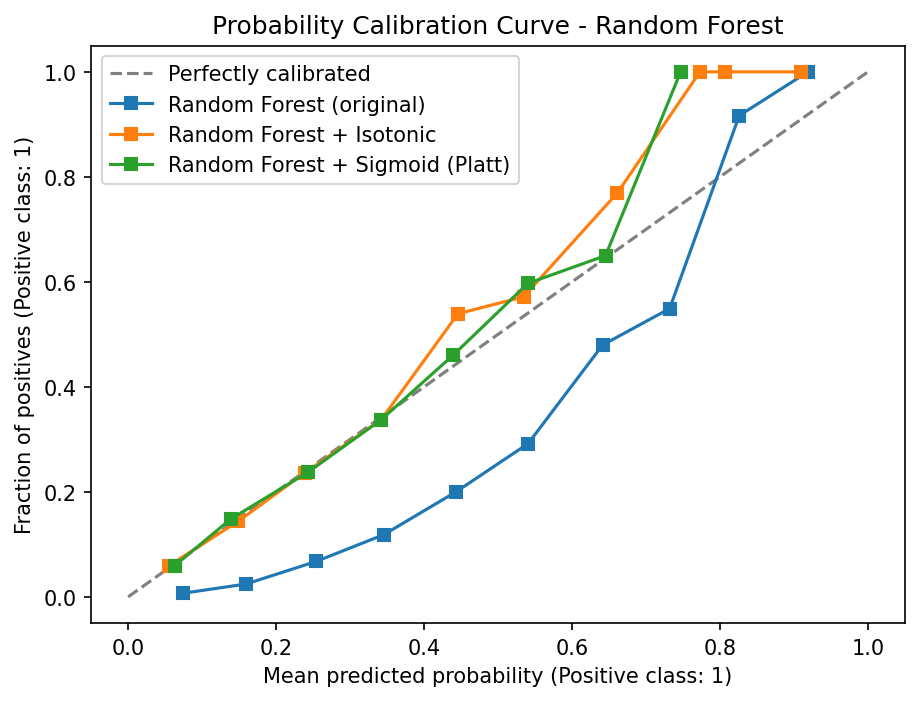

                         Modelo  Umbral  Precision  Recall  F1-score  Especificidad   TN   FP  FN  TP
       Random Forest (original)    0.50      0.366   0.316     0.339          0.915 4977  461 575 266
       Random Forest + Isotonic    0.12      0.215   0.750     0.334          0.577 3136 2302 210 631
Random Forest + Sigmoid (Platt)    0.15      0.260   0.566     0.357          0.751 4086 1352 365 476


In [71]:
# Manual decision threshold for each model (adjust as needed)
thresholds = {
    "Random Forest (original)": 0.50,
    "Random Forest + Isotonic": 0.12,
    "Random Forest + Sigmoid (Platt)": 0.15,
}

# Fit, calibration curve and metrics with the manual threshold
fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Perfectly calibrated")

results = []
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    CalibrationDisplay.from_estimator(clf, X_test, y_test, n_bins=10, name=name, ax=ax)

    thr = thresholds[name]
    proba = clf.predict_proba(X_test)[:, 1]
    y_pred = (proba >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    results.append({
        "Modelo": name,
        "Umbral": thr,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Especificidad": specificity,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

plt.title('Probability Calibration Curve - Random Forest')
plt.legend(loc="best")
plt.show()

print(pd.DataFrame(results).round(3).to_string(index=False))

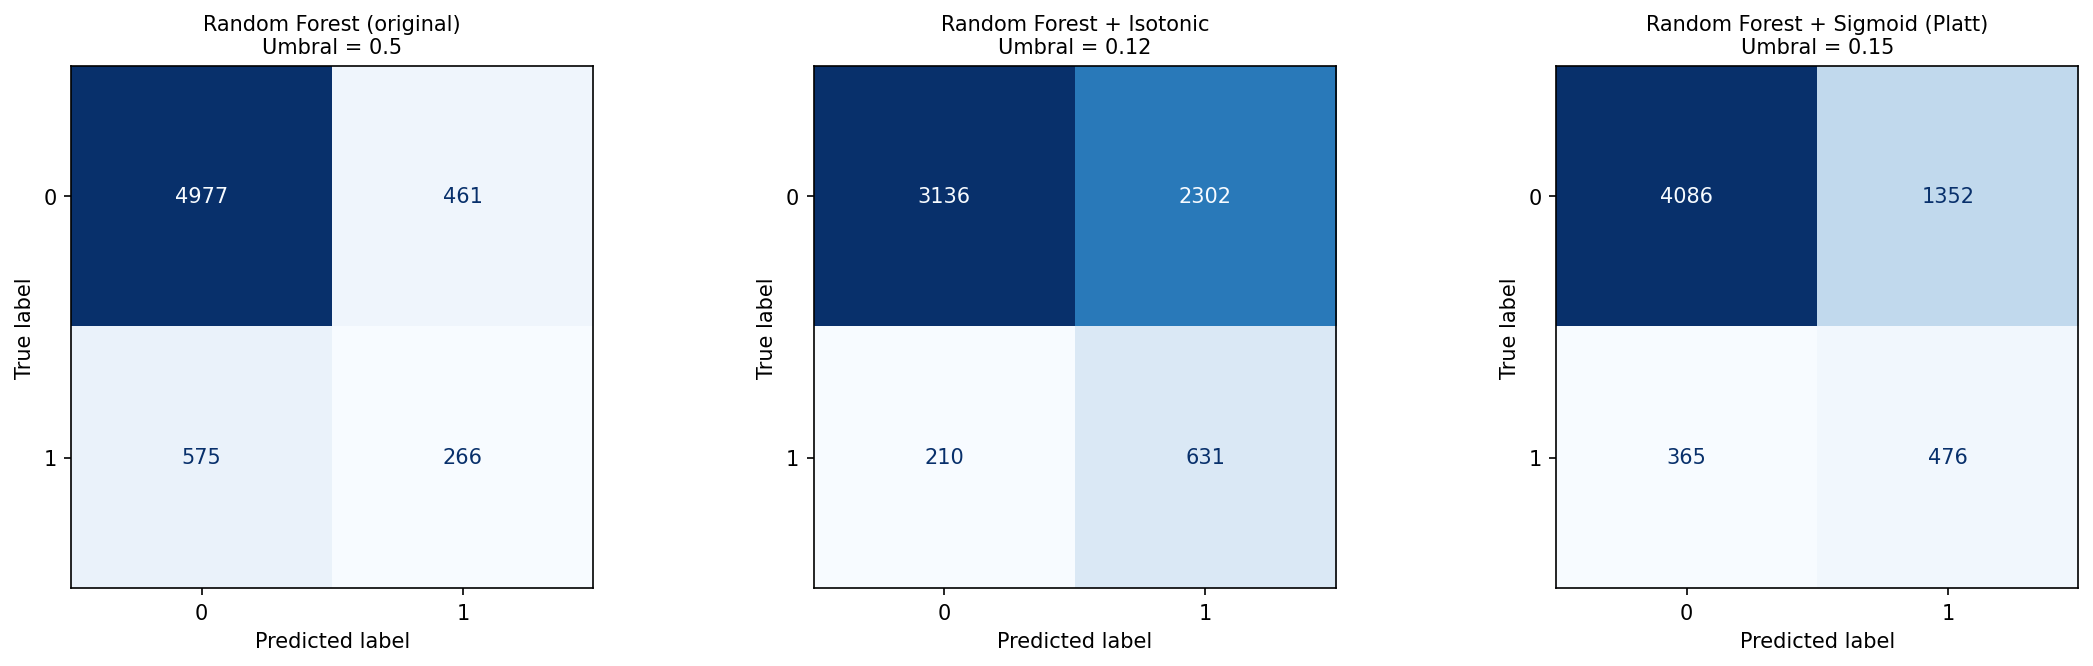

In [72]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(classifiers), figsize=(5 * len(classifiers), 4.5), dpi=150)

for ax, (name, clf) in zip(axes, classifiers.items()):
    thr = thresholds[name]
    proba = clf.predict_proba(X_test)[:, 1]
    y_pred = (proba >= thr).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"{name}\nUmbral = {thr}", fontsize=10)

plt.tight_layout()
plt.show()

In [77]:
import pandas as pd
from sklearn.metrics import classification_report

tablas = {}

for name, clf in classifiers.items():
    thr = thresholds[name]
    proba = clf.predict_proba(X_test)[:, 1]
    y_pred = (proba >= thr).astype(int)

    reporte = classification_report(
        y_test, y_pred, labels=[0, 1], output_dict=True, zero_division=0
    )
    tabla = pd.DataFrame({
        "Clase": [0, 1],
        "Precision": [reporte["0"]["precision"], reporte["1"]["precision"]],
        "Recall/Especificidad": [reporte["0"]["recall"], reporte["1"]["recall"]],
        "F1-score": [reporte["0"]["f1-score"], reporte["1"]["f1-score"]],
    }).round(3)

    tablas[name] = tabla

    print(f"\n{name} (umbral = {thr})")
    print(tabla.to_string(index=False))


Random Forest (original) (umbral = 0.5)
 Clase  Precision  Recall/Especificidad  F1-score
     0      0.896                 0.915     0.906
     1      0.366                 0.316     0.339

Random Forest + Isotonic (umbral = 0.12)
 Clase  Precision  Recall/Especificidad  F1-score
     0      0.937                 0.577     0.714
     1      0.215                 0.750     0.334

Random Forest + Sigmoid (Platt) (umbral = 0.15)
 Clase  Precision  Recall/Especificidad  F1-score
     0      0.918                 0.751     0.826
     1      0.260                 0.566     0.357
